# 🔍 Exploration du German Credit Dataset

Avant d'entraîner un modèle, on regarde les données : qui fait défaut, et quels signaux semblent prédire le risque ?

Source : *Statlog (German Credit Data)*, UCI Machine Learning Repository — 1 000 demandes de crédit, 20 variables, licence CC BY 4.0.

In [1]:
import sys
sys.path.insert(0, "../src")
import matplotlib.pyplot as plt
import pandas as pd
from scoring import data as D

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = D.load_dataset()
print(f"{len(df)} dossiers · {df[D.TARGET].mean():.0%} de défauts")
df[D.FEATURES + [D.TARGET]].head()

1000 dossiers · 30% de défauts


,duree_mois,montant,taux_effort,anciennete_residence,age,nb_credits,nb_personnes_a_charge,statut_compte,historique_credit,objet_credit,epargne,anciennete_emploi,autres_debiteurs,patrimoine,autres_credits,logement,emploi,telephone,defaut
0,6,1169,4,4,67,2,1,négatif (< 0 DM),compte critique / crédits ailleurs,radio / télévision,inconnue / aucune,7 ans ou plus,aucun,immobilier,aucun,propriétaire,qualifié / employé,oui,0
1,48,5951,2,2,22,1,1,0 à 200 DM,crédits en cours remboursés à temps,radio / télévision,moins de 100 DM,1 à 4 ans,aucun,immobilier,aucun,propriétaire,qualifié / employé,non,1
2,12,2096,2,3,49,1,2,pas de compte courant,compte critique / crédits ailleurs,études,moins de 100 DM,4 à 7 ans,aucun,immobilier,aucun,propriétaire,non qualifié,non,0
3,42,7882,2,4,45,1,2,négatif (< 0 DM),crédits en cours remboursés à temps,mobilier / équipement,moins de 100 DM,4 à 7 ans,garant,épargne logement / assurance vie,aucun,logé gratuitement,qualifié / employé,non,0
4,24,4870,3,4,53,2,2,négatif (< 0 DM),retards de paiement passés,voiture neuve,moins de 100 DM,1 à 4 ans,aucun,aucun / inconnu,aucun,logé gratuitement,qualifié / employé,non,1


## 1. Taux de défaut selon le solde du compte courant
Le signal le plus fort du jeu de données.

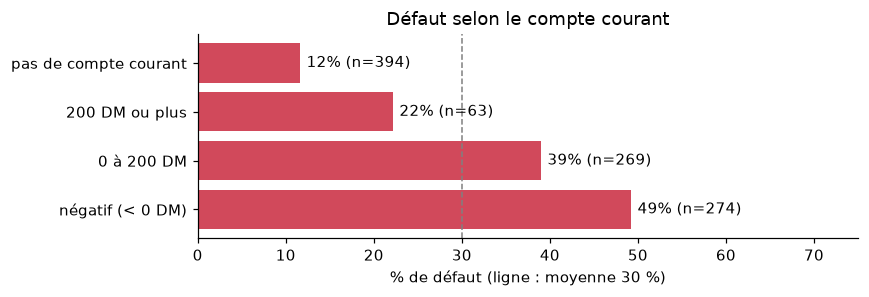

In [2]:
def default_rate(col, order=None):
    g = df.groupby(col)[D.TARGET].agg(["mean", "size"])
    return g.loc[order] if order else g.sort_values("mean")

def bar(g, title):
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(g) + 1))
    bars = ax.barh(g.index, g["mean"] * 100, color="#d1495b")
    ax.bar_label(bars, labels=[f"{m:.0%} (n={n})" for m, n in zip(g["mean"], g["size"])], padding=4)
    ax.axvline(30, color="grey", ls="--", lw=1); ax.set_xlabel("% de défaut (ligne : moyenne 30 %)")
    ax.set_xlim(0, 75); ax.set_title(title); plt.tight_layout(); plt.show()

bar(default_rate("statut_compte", list(D.CODES["statut_compte"].values())), "Défaut selon le compte courant")

**➜ Avec un compte courant négatif, près d'un client sur deux fait défaut (49 %). Sans compte courant dans cette banque, seulement 12 %.**

## 2. Historique de crédit : un résultat contre-intuitif

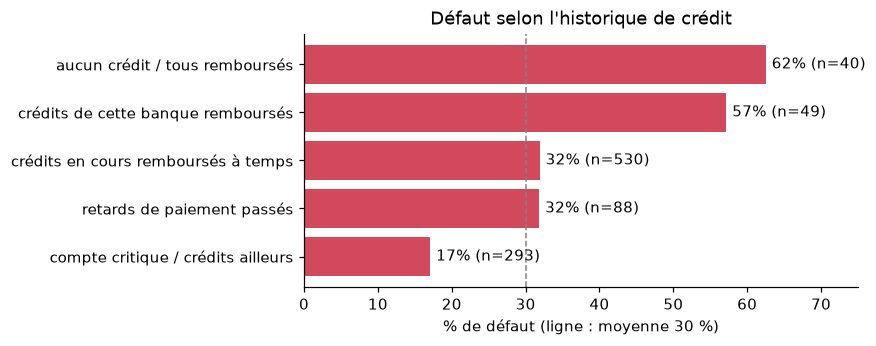

In [3]:
bar(default_rate("historique_credit"), "Défaut selon l'historique de crédit")

**➜ Les clients notés « compte critique / crédits ailleurs » font *moins* défaut (17 %) que ceux sans aucun crédit (63 %).**

Ce paradoxe est connu sur ce jeu de données : un client qui a déjà des crédits ailleurs a été **accepté et suivi** par d'autres prêteurs,
alors qu'un client sans historique est une inconnue. Le modèle apprendra cette relation telle quelle : c'est une limite à garder en tête.

## 3. Durée et montant du crédit

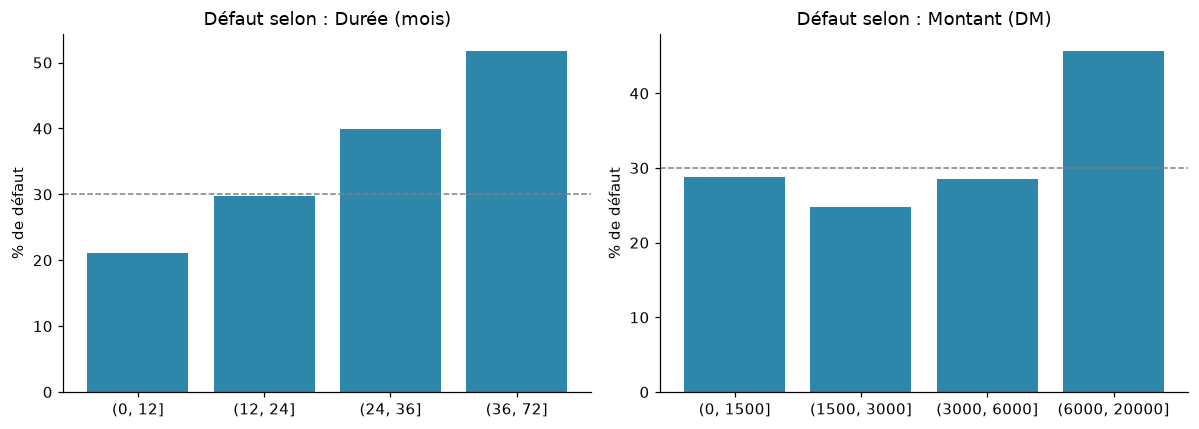

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, bins, label in [(axes[0], "duree_mois", [0, 12, 24, 36, 72], "Durée (mois)"),
                             (axes[1], "montant", [0, 1500, 3000, 6000, 20000], "Montant (DM)")]:
    g = df.groupby(pd.cut(df[col], bins), observed=True)[D.TARGET].mean() * 100
    ax.bar([str(i) for i in g.index], g.values, color="#2e86ab")
    ax.axhline(30, color="grey", ls="--", lw=1); ax.set_title(f"Défaut selon : {label}"); ax.set_ylabel("% de défaut")
plt.tight_layout(); plt.show()

**➜ Le risque augmente régulièrement avec la durée : 21 % jusqu'à 12 mois, 52 % au-delà de 36 mois.** Pour le montant, l'effet n'apparaît vraiment qu'au-delà de 6 000 DM (46 % de défaut).

## 4. Âge et variables sensibles

In [5]:
g = df.groupby(pd.cut(df["age"], [18, 25, 35, 50, 80]), observed=True)[D.TARGET].agg(["mean", "size"])
print("Défaut par âge :"); print(g.round(3))
print("\nDéfaut par sexe :"); print(df.groupby("sexe")[D.TARGET].mean().round(3))

Défaut par âge :
           mean  size
age                  
(18, 25]  0.421   190
(25, 35]  0.296   398
(35, 50]  0.237   299
(50, 80]  0.274   113

Défaut par sexe :
sexe
femme    0.352
homme    0.277
Name: defaut, dtype: float64


Les jeunes et, dans une moindre mesure, les femmes ont un taux de défaut plus élevé dans ces données.
**Le sexe, la situation familiale et la nationalité sont exclus du modèle** : en Europe, refuser un crédit sur ces critères serait discriminatoire.
L'âge est conservé (usage courant en scoring), mais son effet est **audité** après l'entraînement (voir `reports/model_card.md`).

## Ce qu'on retient pour la modélisation
- Cible déséquilibrée (30 % de défauts) → on mesure l'**AUC**, pas la précision brute.
- Erreurs asymétriques (accepter un mauvais payeur coûte 5 fois plus) → seuil choisi par **coût**, pas à 50 %.
- Montant et durée très asymétriques → **logarithme** avant normalisation.
- Seulement 1 000 dossiers → **validation croisée** et modèles peu complexes.